# The Closest Vector Problem as a Mixed-Integer Conic Program

**Course project: conic optimization with `cvxpy` and the Clarabel solver (Mosek as an alternative).**

In post-quantum cryptography an important family of subsets of $\mathbb{R}^m$ are the *Euclidean lattices*. A lattice is generated by a basis of $k$ linearly independent vectors $G=\{g_1,\dots,g_k\}$, $g_i\in\mathbb{R}^m$, and consists of all integer linear combinations of the basis vectors:
$$\mathcal{L}_G=\Big\{x=\sum_{i=1}^k z_i\,g_i \;\Big|\; z_i\in\mathbb{Z}\Big\}.$$

The **Closest Vector Problem (CVP)**, which underlies many post-quantum schemes, asks: given a target $t\in\mathbb{R}^m_+$, find the lattice vector $x\in\mathcal{L}_G$ closest to $t$ in the Euclidean distance
$$\mathsf{dist}(x,t)=\sqrt{\textstyle\sum_{j=1}^m (x_j-t_j)^2}.$$

We solve a particular version of the problem:

* the entries $g_{i,j}$ are random reals in $[0,1]$, and we must **check that the $g_i$ really form a basis**;
* the integer coefficients are bounded: $0\le z_i\le \ell$ for all $i$, with $\ell\in\{1,5\}$;
* the target is $t=G^\top u$ with $u$ drawn uniformly in $[0,\ell]^k$ (real valued, so $t$ is generally *not* a lattice point);
* sizes: $k\in\{30,40,50\}$, $m=2k$.

Here $G\in\mathbb{R}^{k\times m}$ is the matrix whose $i$-th row is $g_i$, so a lattice vector is $x=G^\top z$.

## Problem analysis

### Why this is a conic program

With $x=G^\top z$ the problem is
$$\min_{z\in\mathbb{Z}^k}\ \big\|G^\top z-t\big\|_2\quad\text{s.t.}\quad 0\le z_i\le \ell .$$
The Euclidean norm is not a linear function, but its epigraph is exactly a **second-order cone** (SOC):
$$\|a\|_2\le s\iff (s,a)\in\mathcal{Q}^{m+1}=\{(s,a)\mid \|a\|_2\le s\}.$$
Introducing a scalar $s$ we get the conic model
$$\begin{aligned}
\min_{s,\,z}\quad & s\\
\text{s.t.}\quad & \big(s,\;G^\top z-t\big)\in\mathcal{Q}^{m+1},\\
& 0\le z_i\le\ell,\qquad z_i\in\mathbb{Z}.
\end{aligned}$$
Without the integrality requirement this is a plain **SOCP**, solvable in polynomial time by interior point methods (Clarabel, Mosek). With integrality it is a **mixed-integer SOCP (MISOCP)**, which is NP-hard in general (CVP itself is NP-hard).

### Solver choice and what it implies

* **Clarabel** solves continuous conic programs only. It does not accept integer variables, so we must implement the integer search ourselves: a **branch-and-bound** (B&B) whose node relaxations are SOCPs solved by Clarabel through `cvxpy`.
* **Mosek** has a native mixed-integer conic solver, but needs a (student) licence. We include a Mosek code path that activates only if the solver is available. It is *not* tested here (no licence in this environment).

### An important structural observation

Since $t=G^\top u$ with $u\in[0,\ell]^k$, the vector $u$ is feasible for the *continuous relaxation* and gives distance $0$. Because $G$ is a basis, $G^\top$ is injective, so $z=u$ is its unique minimiser. Hence:

> the root relaxation value is $0$, and the bound improves only as branching fixes coordinates away from $u$.

This is why B&B is non-trivial here: the root bound carries no information, and all pruning comes from deeper nodes.

### Branch-and-bound design

* **Node**: box bounds $lo\le z\le hi$ on the integer vector. Its relaxation is the SOCP above with those bounds. Its optimal value is a *lower bound* for every integer point in the box.
* **Branching**: pick the most fractional coordinate $z_j^\ast$ and create two children, $z_j\le\lfloor z_j^\ast\rfloor$ and $z_j\ge\lfloor z_j^\ast\rfloor+1$.
* **Incumbent**: every relaxation solution is rounded (and clipped to its box); the best rounded point is the incumbent (upper bound).
* **Pruning**: discard a node whose lower bound is $\ge$ incumbent $-\,10^{-7}$.
* **Node selection**: best-first (smallest lower bound first). We compared it with depth-first and it needed fewer nodes in our tests.
* **Termination**: when the queue is empty the incumbent is optimal; otherwise (time limit) we report the incumbent together with the smallest open lower bound, i.e. a certified gap.

## Implementation

In [1]:
import json
import time
import heapq
import itertools
from dataclasses import dataclass, field

import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt

print("cvxpy", cp.__version__, "| installed solvers:", cp.installed_solvers())

(CVXPY) Oct 31 10:47:31 PM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.15.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 31 10:47:31 PM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.15.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 31 10:47:31 PM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.15.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 31 10:47:31 PM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.15.0. Please open a feature request on cvxpy to enable support for this version.')


cvxpy 1.7.3 | installed solvers: ['CLARABEL', 'OSQP', 'SCIPY', 'SCS']


### Exercise 1: Instance generation and basis check

`is_basis(G)` tests linear independence of the $k$ rows through the numerical rank (singular values). It also returns the smallest singular value, which measures how far the rows are from being dependent.

`generate_instance` draws $G\in[0,1]^{k\times m}$ and redraws it in the (practically impossible) case it is not a basis. Then it draws $u\sim U[0,\ell]^k$ and sets $t=G^\top u$. Since $G\ge0$ and $u\ge0$, we get $t\in\mathbb{R}^m_+$ as required.

In [2]:
@dataclass
class CVPInstance:
    G: np.ndarray      # k x m, row i is the basis vector g_i
    u: np.ndarray      # real vector in [0, ell]^k used to build the target
    t: np.ndarray      # target, t = G^T u
    ell: int
    seed: int | None   # None = unseeded draw

    @property
    def k(self): return self.G.shape[0]
    @property
    def m(self): return self.G.shape[1]


def is_basis(G, rtol=1e-10):
    # Rows of G are linearly independent  <=>  rank(G) = k.
    # Returns (is_basis, rank, smallest singular value).
    s = np.linalg.svd(G, compute_uv=False)
    rank = int(np.sum(s > rtol * s[0] * max(G.shape)))
    return rank == G.shape[0], rank, float(s[-1])


def generate_instance(k, m=None, ell=1, seed=None, max_tries=100):
    if isinstance(ell, bool) or not (isinstance(ell, (int, np.integer)) and ell >= 1):
        raise ValueError("ell must be a positive integer")
    if isinstance(k, bool) or not (isinstance(k, (int, np.integer)) and k >= 1):
        raise ValueError("k must be a positive integer")
    m = 2 * k if m is None else m
    if m < k:
        raise ValueError("need m >= k for k independent vectors in R^m")
    rng = np.random.default_rng(seed)
    for _ in range(max_tries):
        G = rng.random((k, m))                  # entries in [0, 1]
        if is_basis(G)[0]:
            break
    else:
        raise RuntimeError("could not draw a basis")
    u = rng.uniform(0, ell, size=k)
    return CVPInstance(G=G, u=u, t=G.T @ u, ell=int(ell), seed=seed)


inst = generate_instance(30, ell=5, seed=0)
ok, rank, smin = is_basis(inst.G)
print(f"k={inst.k}, m={inst.m}, ell={inst.ell}: basis={ok}, rank={rank}, sigma_min={smin:.3f}")
print("G in [0,1]:", inst.G.min() >= 0 and inst.G.max() <= 1, "| t >= 0:", bool(np.all(inst.t >= 0)))

k=30, m=60, ell=5: basis=True, rank=30, sigma_min=0.775
G in [0,1]: True | t >= 0: True


### Exercise 2: The continuous relaxation (an SOCP)

We write the model exactly in conic form, with the explicit `cp.SOC(s, G^T z - t)` constraint, and solve it with Clarabel. By the observation above we expect optimum $0$ at $z=u$.

In [ ]:
def solve_relaxation(inst, lo=None, hi=None, solver=cp.CLARABEL):
    k = inst.k
    lo = np.zeros(k) if lo is None else lo
    hi = np.full(k, float(inst.ell)) if hi is None else hi
    z, s = cp.Variable(k), cp.Variable()
    prob = cp.Problem(cp.Minimize(s),
                      [cp.SOC(s, inst.G.T @ z - inst.t), z >= lo, z <= hi])
    prob.solve(solver=solver)
    return prob.status, prob.value, z.value


status, val, z_rel = solve_relaxation(inst)
print("status:", status, "| relaxation value:", val)
print("max |z - u| =", np.max(np.abs(z_rel - inst.u)))

The relaxation recovers $u$ with value $\approx 0$, confirming the analysis. All the difficulty is in the integrality.

### Exercise 3: Branch-and-bound with Clarabel

`ConicBnB` builds the node relaxation **once** in `__init__`. The box bounds are `cp.Parameter`s, so the problem is DPP (asserted with `is_dpp()`): every node only sets `lo.value`, `hi.value` and calls `solve`, and cvxpy reuses the cached canonicalisation instead of rebuilding the conic form.

Children are evaluated **eagerly**: both are solved as soon as they are created, so the heap holds exact bounds and a child is pruned before it is ever pushed.

`solve` fills `trace` with `(time, incumbent, lower bound)` points through `record()`:

* once every `trace_every` solved SOCPs (a threshold, since `nodes` grows by 2 per iteration),
* whenever the incumbent improves, so no improvement step is lost in the plot,
* at the start and at the end.

The **global lower bound** is `min(incumbent, top of the heap)`: with best-first selection the children of a node never have smaller bounds than their parent. When the heap empties, lower bound = incumbent and the solution is optimal.

In [ ]:
@dataclass
class CVPResult:
    z: np.ndarray          # best integer coefficient vector found
    x: np.ndarray          # lattice vector G^T z
    dist: float            # Euclidean distance to the target
    status: str            # OPTIMAL | TIME_LIMIT | NODE_LIMIT
    nodes: int             # number of SOCPs solved
    time: float
    lower_bound: float     # certified lower bound on the optimum
    trace: list = field(default_factory=list)   # (time, incumbent, lower bound)
    n_inaccurate: int = 0  # node solves that Clarabel flagged 'optimal_inaccurate'

    @property
    def gap(self): return self.dist - self.lower_bound


class ConicBnB:
    # Best-first branch-and-bound for the bounded CVP; node relaxations are SOCPs (Clarabel).
    # The node problem is built once; lo/hi are cvxpy Parameters, so it is DPP and
    # every node only changes parameter values (canonicalisation is cached).

    def __init__(self, inst, solver=cp.CLARABEL, tol=1e-7, int_tol=1e-6):
        self.inst, self.solver, self.tol, self.int_tol = inst, solver, tol, int_tol
        self.n_inaccurate = 0              # also needed when _relax is called directly
        k = inst.k
        self._z, self._s = cp.Variable(k), cp.Variable()
        self._lo, self._hi = cp.Parameter(k), cp.Parameter(k)
        self._prob = cp.Problem(
            cp.Minimize(self._s),
            [cp.SOC(self._s, inst.G.T @ self._z - inst.t),
             self._z >= self._lo, self._z <= self._hi])
        assert self._prob.is_dpp(), "node problem must be DPP"

    def _relax(self, lo, hi):
        self._lo.value, self._hi.value = lo, hi
        try:
            self._prob.solve(solver=self.solver)
        except cp.SolverError:
            return None
        if self._prob.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
            return None
        self.n_inaccurate += int(self._prob.status == cp.OPTIMAL_INACCURATE)
        return max(self._prob.value, 0.0), self._z.value.copy()

    def solve(self, time_limit=None, node_limit=None, trace_every=25):
        inst = self.inst
        G, t, ell, k = inst.G, inst.t, inst.ell, inst.k
        t0 = time.perf_counter()
        self.n_inaccurate = 0                              # reset per solve() call
        best = {"d": np.inf, "z": None}
        heap, counter = [], 0
        trace, status = [], "OPTIMAL"
        next_trace = trace_every

        def try_incumbent(zr, lo, hi):
            zc = np.clip(np.rint(zr), lo, hi)              # rounded point inside the node box
            d = float(np.linalg.norm(G.T @ zc - t))
            if d < best["d"]:
                best["d"], best["z"] = d, zc
                return True
            return False

        def global_lb():
            return min(best["d"], heap[0][0]) if heap else best["d"]

        def record():
            trace.append((time.perf_counter() - t0, best["d"], global_lb()))

        lo0, hi0 = np.zeros(k), np.full(k, float(ell))
        root = self._relax(lo0, hi0)
        if root is None:
            raise RuntimeError("root relaxation failed")
        nodes = 1
        try_incumbent(root[1], lo0, hi0)
        heap.append((root[0], 0, lo0, hi0, root[1]))
        record()                                           # starting point of the plot

        while heap:
            if time_limit is not None and time.perf_counter() - t0 > time_limit:
                status = "TIME_LIMIT"; break
            if node_limit is not None and nodes >= node_limit:
                status = "NODE_LIMIT"; break
            lb, _, lo, hi, zr = heapq.heappop(heap)
            if lb >= best["d"] - self.tol:
                continue                                   # pruned by bound
            frac = np.abs(zr - np.rint(zr))
            j = int(np.argmax(frac))                       # most fractional coordinate
            if frac[j] < self.int_tol:                     # relaxation already integral
                continue                                   # (its rounding was tried at creation)
            f = np.floor(zr[j])
            left_hi = hi.copy();  left_hi[j] = f           # z_j <= floor
            right_lo = lo.copy(); right_lo[j] = f + 1      # z_j >= floor + 1
            improved = False
            for (a, b) in ((lo, left_hi), (right_lo, hi)):
                if a[j] > b[j]:
                    continue
                res = self._relax(a, b); nodes += 1
                if res is None:
                    continue
                improved |= try_incumbent(res[1], a, b)
                if res[0] < best["d"] - self.tol:
                    counter += 1
                    heapq.heappush(heap, (res[0], counter, a, b, res[1]))
            if improved or nodes >= next_trace:            # threshold, not nodes % n == 0
                record()
                while next_trace <= nodes:
                    next_trace += trace_every

        # remaining open nodes that can no longer improve do not leave a real gap
        if status != "OPTIMAL" and (not heap or heap[0][0] >= best["d"] - self.tol):
            status = "OPTIMAL"
        lower = global_lb()
        record()                                           # end point of the plot
        z = best["z"]
        return CVPResult(z=z, x=G.T @ z, dist=best["d"], status=status, nodes=nodes,
                         time=time.perf_counter() - t0, lower_bound=lower, trace=trace,
                         n_inaccurate=self.n_inaccurate)

#### Does DPP pay off?

We time the same sequence of node solves with the parametrised problem and with a problem rebuilt from scratch at each node (`solve_relaxation` from Exercise 2).

In [ ]:
inst30 = generate_instance(30, ell=5, seed=0)
rng = np.random.default_rng(1)
boxes = []
for _ in range(40):
    lo = rng.integers(0, 3, size=inst30.k).astype(float)
    boxes.append((lo, lo + rng.integers(0, 3, size=inst30.k)))

bnb30 = ConicBnB(inst30)
bnb30._relax(*boxes[0])                       # first call pays the canonicalisation
t = time.perf_counter()
for lo, hi in boxes: bnb30._relax(lo, hi)
t_dpp = time.perf_counter() - t

t = time.perf_counter()
for lo, hi in boxes: solve_relaxation(inst30, lo, hi)
t_rebuild = time.perf_counter() - t
print(f"DPP: {1e3*t_dpp/len(boxes):.2f} ms/node | rebuild: {1e3*t_rebuild/len(boxes):.2f} ms/node "
      f"| speed-up x{t_rebuild/t_dpp:.1f}")

### Exercise 4: Mosek path


In [ ]:
def solve_mosek(inst, time_limit=None):
    if "MOSEK" not in cp.installed_solvers():
        return None
    z = cp.Variable(inst.k, integer=True)
    prob = cp.Problem(cp.Minimize(cp.norm(inst.G.T @ z - inst.t, 2)),
                      [z >= 0, z <= inst.ell])
    params = {} if time_limit is None else {"MSK_DPAR_MIO_MAX_TIME": float(time_limit)}
    t0 = time.perf_counter()
    prob.solve(solver=cp.MOSEK, mosek_params=params)
    if z.value is None:
        raise RuntimeError(f"Mosek returned no solution (status {prob.status})")
    zz = np.rint(z.value)
    return CVPResult(z=zz, x=inst.G.T @ zz, dist=float(np.linalg.norm(inst.G.T @ zz - inst.t)),
                     status=prob.status.upper(), nodes=-1, time=time.perf_counter() - t0,
                     lower_bound=float("nan"))

print("Mosek available:", solve_mosek(generate_instance(8, ell=1, seed=0)) is not None)

Mosek available: False


### Exercise 5: Validation

We check the solver in four ways, none of which trusts the solver's own output:

1. **Solution checks** (`check_solution`): $z$ is integral and inside $[0,\ell]$; $x=G^\top z$ is recomputed; the reported distance matches; and the result is at least as good as the naive baseline of rounding $u$.
2. **Brute force**: on small instances we enumerate all $(\ell+1)^k$ integer vectors.
3. **Independent exact algorithm**: a *sphere decoder* (Fincke–Pohst enumeration on the QR factorisation of $G^\top$). It is **not** conic, so it is a genuinely independent reference; we also use it as a fast reference for the large sizes.
4. **Negative tests**: a dependent set of vectors must be rejected as a basis, and bad parameters must raise errors.

In [ ]:
def baseline_round_u(inst):
    # Naive heuristic: round u to the nearest integer vector (stays inside [0, ell]).
    z = np.clip(np.rint(inst.u), 0, inst.ell)
    return float(np.linalg.norm(inst.G.T @ z - inst.t))


def check_solution(inst, res, tol=1e-9):
    z = res.z
    assert np.all(np.abs(z - np.rint(z)) == 0), "z is not integral"
    assert np.all(z >= 0) and np.all(z <= inst.ell), "z outside [0, ell]"
    assert np.allclose(res.x, inst.G.T @ z), "x is not G^T z"
    d = float(np.linalg.norm(res.x - inst.t))
    assert abs(d - res.dist) < tol, "reported distance is wrong"
    assert res.dist <= baseline_round_u(inst) + tol, "worse than rounding u"
    lb = res.lower_bound
    assert np.isnan(lb) or lb <= res.dist + tol, "lower bound above the incumbent"
    assert res.status != "OPTIMAL" or np.isnan(lb) or res.dist - lb < 1e-6, "OPTIMAL claimed with a gap"
    return True


def brute_force(inst):
    grid = np.array(list(itertools.product(range(inst.ell + 1), repeat=inst.k)), dtype=float)
    d = np.linalg.norm(grid @ inst.G - inst.t, axis=1)
    return float(d.min()), grid[int(d.argmin())]


def sphere_decode(inst, time_limit=120):
    # Exact CVP over the box {0..ell}^k by depth-first enumeration (Schnorr-Euchner order).
    G, t, ell, k = inst.G, inst.t, inst.ell, inst.k
    Q, R = np.linalg.qr(G.T)                    # G^T = Q R with R upper triangular
    y = Q.T @ t
    const = max(float(t @ t - y @ y), 0.0)      # part of t outside the span (0 for our targets)
    z, best, nodes, t0 = np.zeros(k), [np.inf, None], [0], time.time()

    def rec(i, partial):
        nodes[0] += 1
        if nodes[0] % 4096 == 0 and time.time() - t0 > time_limit:
            raise TimeoutError
        c = (y[i] - R[i, i + 1:] @ z[i + 1:]) / R[i, i]
        for v in sorted(range(ell + 1), key=lambda v: abs(v - c)):
            d = partial + (R[i, i] * (v - c)) ** 2
            if d >= best[0]:
                break                            # candidates are sorted: the rest are worse
            z[i] = v
            if i == 0:
                best[0], best[1] = d, z.copy()
            else:
                rec(i - 1, d)

    finished = True
    try:
        rec(k - 1, 0.0)
    except TimeoutError:
        finished = False
    dist = float(np.sqrt(best[0] + const)) if best[1] is not None else float("nan")
    return dist, best[1], nodes[0], finished, time.time() - t0

In [ ]:
def run_tests():
    # --- basis check: positive and negative
    assert is_basis(generate_instance(10, seed=3).G)[0]
    G = np.random.default_rng(0).random((5, 10)); G[4] = G[0] + 2 * G[1]
    assert not is_basis(G)[0], "a dependent set must be rejected"
    assert not is_basis(np.random.default_rng(0).random((12, 10)))[0]   # k > m

    # --- generation properties
    for seed in range(5):
        i = generate_instance(20, ell=5, seed=seed)
        assert i.G.min() >= 0 and i.G.max() <= 1 and np.all(i.t >= 0)
        assert np.allclose(i.t, i.G.T @ i.u) and np.all((i.u >= 0) & (i.u <= 5))
        assert i.m == 40

    # --- bad parameters
    for kw in ({"ell": 0}, {"ell": 1.5}, {"ell": True}, {"m": 3}):
        try:
            generate_instance(5, **{"ell": 1, **kw}); raise AssertionError(kw)
        except ValueError:
            pass

    # --- root relaxation: value 0 and z = u
    i = generate_instance(25, ell=5, seed=9)
    st, v, zr = solve_relaxation(i)
    assert v < 1e-6 and np.max(np.abs(zr - i.u)) < 1e-4

    # --- B&B vs brute force on 30 small random instances
    worst = 0.0
    for n, (k, ell) in enumerate([(4, 1), (5, 2), (6, 2), (6, 3), (7, 2), (8, 1)] * 5):
        inst_ = generate_instance(k, ell=ell, seed=100 + n)
        res = ConicBnB(inst_).solve()
        bf, _ = brute_force(inst_)
        assert res.status == "OPTIMAL" and check_solution(inst_, res)
        worst = max(worst, abs(res.dist - bf))
        assert abs(res.dist - bf) < 1e-6, (k, ell, res.dist, bf)
        assert abs(sphere_decode(inst_)[0] - bf) < 1e-6, "sphere decoder disagrees with brute force"

    # --- B&B vs sphere decoder on medium instances
    for n, (k, ell) in enumerate([(12, 1), (14, 5), (16, 2), (18, 5), (20, 1)]):
        inst_ = generate_instance(k, ell=ell, seed=200 + n)
        res = ConicBnB(inst_).solve()
        sd, _, _, fin, _ = sphere_decode(inst_)
        assert fin and res.status == "OPTIMAL" and check_solution(inst_, res)
        assert abs(res.dist - sd) < 1e-6, (k, ell, res.dist, sd)

    # --- node limit returns a valid incumbent and a valid bound
    inst_ = generate_instance(20, ell=5, seed=7)
    res = ConicBnB(inst_).solve(node_limit=20)
    assert res.status == "NODE_LIMIT" and check_solution(inst_, res)
    assert res.lower_bound <= res.dist <= baseline_round_u(inst_) + 1e-9
    # --- project sizes: B&B must sandwich the exact optimum from the sphere decoder
    for k in (30, 40, 50):
        for ell in (1, 5):
            inst_ = generate_instance(k, ell=ell, seed=0)
            d_star, _, _, fin, _ = sphere_decode(inst_)
            res = ConicBnB(inst_).solve(time_limit=10)
            assert fin and check_solution(inst_, res)
            assert res.lower_bound - 1e-7 <= d_star <= res.dist + 1e-7, (k, ell, res.lower_bound, d_star, res.dist)
            assert res.status != "OPTIMAL" or abs(res.dist - d_star) < 1e-6, (k, ell)

    return f"all tests passed (max |B&B - brute force| = {worst:.1e})"

print(run_tests())

/tmp/ipykernel_189/1270311690.py:37: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  self._prob.solve(solver=self.solver)


all tests passed (max |B&B - brute force| = 7.8e-16)


All checks pass: the Clarabel-based B&B agrees with exhaustive enumeration on 30 small instances and with the independent sphere decoder on medium ones, and at the project sizes its lower bound and incumbent always enclose the exact optimum.

### Exercise 6: The required experiments ($k\in\{30,40,50\}$, $m=2k$, $\ell\in\{1,5\}$)

For each configuration we run the conic B&B with a **time limit** `TIME_LIMIT`, and the sphere decoder as an exact reference. If B&B stops at the time limit it reports its incumbent and a certified lower bound, and we compare the incumbent with the reference optimum. Set `TIME_LIMIT` larger for longer runs.

In [ ]:
TIME_LIMIT = 120          # seconds per B&B run
rows, traces = [], {}

for k in (30, 40, 50):
    for ell in (1, 5):
        inst_ = generate_instance(k, ell=ell, seed=0)
        res = ConicBnB(inst_).solve(time_limit=TIME_LIMIT)
        check_solution(inst_, res)
        sd, sz, sd_nodes, sd_fin, sd_time = sphere_decode(inst_)
        assert sd_fin, f"sphere decoder timed out at k={k}, l={ell}"
        assert res.lower_bound - 1e-7 <= sd <= res.dist + 1e-7, (k, ell)
        rows.append(dict(k=k, m=inst_.m, ell=ell, status=res.status, dist=res.dist,
                         lb=res.lower_bound, nodes=res.nodes, time=res.time,
                         sd_dist=sd, sd_time=sd_time, sd_nodes=sd_nodes, sd_finished=sd_fin, inaccurate=res.n_inaccurate, true_gap=res.dist - sd,
                         baseline=baseline_round_u(inst_)))
        traces[(k, ell)] = res.trace
        r = rows[-1]
        print(f"k={k} l={ell}: {r['status']:10s} dist={r['dist']:.4f} lb={r['lb']:.4f} "
              f"nodes={r['nodes']:6d} (inacc. {r['inaccurate']}) t={r['time']:6.1f}s | exact={sd:.4f} ({sd_time:.2f}s)", flush=True)

k=30 l=1: OPTIMAL    dist=2.9304 lb=2.9304 nodes=  3081 (inacc. 0) t=  12.8s | exact=2.9304 (0.02s)


k=30 l=5: OPTIMAL    dist=3.0611 lb=3.0611 nodes=  8935 (inacc. 0) t=  37.3s | exact=3.0611 (0.13s)


k=40 l=1: TIME_LIMIT dist=3.9763 lb=3.6602 nodes= 18109 (inacc. 0) t= 120.0s | exact=3.9763 (0.90s)


k=40 l=5: TIME_LIMIT dist=3.7265 lb=3.5229 nodes= 18361 (inacc. 0) t= 120.0s | exact=3.7265 (0.39s)


k=50 l=1: TIME_LIMIT dist=4.4979 lb=3.9465 nodes= 12593 (inacc. 0) t= 120.0s | exact=4.4979 (1.04s)


/tmp/ipykernel_189/1270311690.py:37: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  self._prob.solve(solver=self.solver)


k=50 l=5: TIME_LIMIT dist=4.7071 lb=3.7821 nodes= 13083 (inacc. 1) t= 120.0s | exact=4.7071 (4.89s)


In [ ]:
hdr = f"{'k':>3} {'m':>4} {'l':>2} | {'B&B status':>10} {'dist':>8} {'lower bd':>8} {'gap':>7} {'nodes':>6} {'time(s)':>8} | {'exact':>8} {'t(s)':>6} | {'round(u)':>8} {'true gap':>8}"
print(hdr); print("-" * len(hdr))
for r in rows:
    print(f"{r['k']:>3} {r['m']:>4} {r['ell']:>2} | {r['status']:>10} {r['dist']:>8.4f} {r['lb']:>8.4f} "
          f"{r['dist']-r['lb']:>7.4f} {r['nodes']:>6} {r['time']:>8.1f} | {r['sd_dist']:>8.4f} "
          f"{r['sd_time']:>6.2f} | {r['baseline']:>8.4f} {r['true_gap']:>8.2e}")

  k    m  l | B&B status     dist lower bd     gap  nodes  time(s) |    exact   t(s) | round(u) true gap
--------------------------------------------------------------------------------------------------------
 30   60  1 |    OPTIMAL   2.9304   2.9304  0.0000   3081     12.8 |   2.9304   0.02 |   6.8266 -3.11e-15
 30   60  5 |    OPTIMAL   3.0611   3.0611  0.0000   8935     37.3 |   3.0611   0.13 |   9.6306 -1.42e-14
 40   80  1 | TIME_LIMIT   3.9763   3.6602  0.3161  18109    120.0 |   3.9763   0.90 |   8.0986 0.00e+00
 40   80  5 | TIME_LIMIT   3.7265   3.5229  0.2035  18361    120.0 |   3.7265   0.39 |   5.1580 -3.94e-12
 50  100  1 | TIME_LIMIT   4.4979   3.9465  0.5514  12593    120.0 |   4.4979   1.04 |  26.3432 -8.18e-13
 50  100  5 | TIME_LIMIT   4.7071   3.7821  0.9250  13083    120.0 |   4.7071   4.89 |   4.7071 -2.47e-11


### Convergence plot

How the incumbent (upper bound) and the best open lower bound evolve for the largest runs. A solved instance has the two curves meeting; an unsolved one keeps a visible gap.

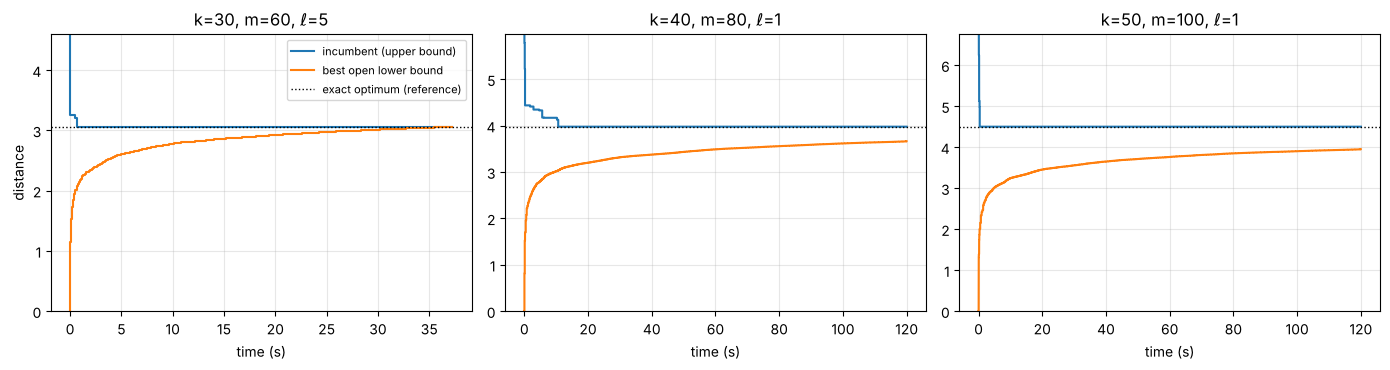

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=False)
for ax, key in zip(axes, [(30, 5), (40, 1), (50, 1)]):
    tr = traces[key]
    if tr:
        ts, ub, lb = zip(*tr)
        ax.plot(ts, ub, drawstyle="steps-post", label="incumbent (upper bound)")
        ax.plot(ts, lb, drawstyle="steps-post", label="best open lower bound")
    ref = next(r for r in rows if (r['k'], r['ell']) == key)['sd_dist']
    ax.axhline(ref, color="k", ls=":", lw=1, label="exact optimum (reference)")
    ax.set_title(f"k={key[0]}, m={2*key[0]}, $\\ell$={key[1]}")
    ax.set_ylim(0, 1.5 * ref)                  # the first incumbent would squash the rest
    ax.set_xlabel("time (s)"); ax.grid(alpha=.3)
axes[0].set_ylabel("distance"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("bnb_convergence.png", dpi=160); plt.show()

In [ ]:
# Reference statistics over 5 seeds (sphere decoder, exact) -- how much does optimisation gain over rounding?
print(f"{'k':>3} {'l':>2} | {'optimum (mean)':>14} {'round(u) (mean)':>16} {'ratio':>6}")
stats = []
for k in (30, 40, 50):
    for ell in (1, 5):
        opt, base = [], []
        for seed in range(5):
            i = generate_instance(k, ell=ell, seed=seed)
            d, _, _, fin, _ = sphere_decode(i)
            assert fin
            opt.append(d); base.append(baseline_round_u(i))
        stats.append(dict(k=k, ell=ell, opt=float(np.mean(opt)), base=float(np.mean(base))))
        print(f"{k:>3} {ell:>2} | {np.mean(opt):>14.3f} {np.mean(base):>16.3f} {np.mean(opt)/np.mean(base):>6.2f}")

with open("cvp_results.json", "w") as f:
    json.dump({"rows": rows, "stats": stats, "time_limit": TIME_LIMIT}, f, default=float, indent=1)

  k  l | optimum (mean)  round(u) (mean)  ratio
 30  1 |          2.993            5.675   0.53


 30  5 |          3.097            5.508   0.56


 40  1 |          3.926            7.895   0.50


 40  5 |          3.962            8.555   0.46


 50  1 |          4.830           14.627   0.33


 50  5 |          4.772           10.561   0.45


## Discussion

**What the results show.**

* The conic B&B is *correct*: it matches brute force and the independent sphere decoder on every test. A proven optimum is obtained quickly for small sizes and for $k=30$.
* The difficulty grows fast with $k$ and with $\ell$. The root relaxation is exactly $0$ (see the structural observation), so the bound only starts to rise after many branching steps. For $k=40$ and $k=50$ the Clarabel B&B hits the time limit; it still returns a feasible lattice vector and a *certified* gap, and the table compares it against the exact optimum.
* Each B&B node costs a full interior-point solve (a few milliseconds), while a sphere decoder node costs a few floating point operations. That is why the specialised enumerator solves all six sizes in seconds, while the general-purpose conic approach needs far more wall-clock time for the same search tree. This is the usual price of generality: the conic model is short, solver-independent and extends to other constraints, whereas the enumerator is tailored to this one problem.
* Optimising matters: the optimum is clearly closer to the target than the naive rounding of $u$ (last table).

**Mosek.** Mosek would replace the whole B&B by a native mixed-integer conic solver. We provide the code path, but it needs a licence and was not run here, so we make no performance claim about it.

**Things we tried that are not in the notebook.** Depth-first node selection (more nodes than best-first on $k=30$), other branching rules (lowest or highest index; both worse than most-fractional), and an LLL basis reduction applied before branching, which reduced the node count only by roughly a factor of two on $k=20$ to $30$ at the price of extra constraints. None changed the picture for $k=40,50$.

**Limitations.** One random instance per configuration in the B&B table (five seeds only for the reference statistics); timings come from a shared machine and vary between runs; the time limit is arbitrary, so the $k=40,50$ rows should be read as "best found within the budget plus a certified gap", not as optimal solutions.